# Incident triage — Data pipeline
## 1. The raw data

In [1]:
from pathlib import Path
import runpy
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if Path("data/raw").exists() else Path.cwd().parent
raw = pd.read_csv(ROOT / "data/raw/incident_event_log.csv", dtype=str, na_values="?")
print(f"{len(raw):,} events | {len(raw.columns)} columns | {raw.number.nunique():,} incidents")
display(raw[["number", "incident_state", "category", "priority", "assignment_group"]].head(5))

141,712 events | 36 columns | 24,918 incidents


,number,incident_state,category,priority,assignment_group
0,INC0000045,New,Category 55,3 - Moderate,Group 56
1,INC0000045,Resolved,Category 55,3 - Moderate,Group 56
2,INC0000045,Resolved,Category 55,3 - Moderate,Group 56
3,INC0000045,Closed,Category 55,3 - Moderate,Group 56
4,INC0000047,New,Category 40,3 - Moderate,Group 70


ServiceNow incident histories: several updates can belong to one ticket. Our targets are the initial **priority** and **assignment group**. Missing values are recorded as `?`.

## 2. We added some noise
Category spacing/case, alternative date formats and duplicate rows. Seed **774**; dates and target values were preserved.

In [2]:
noisy = pd.read_csv(ROOT / "data/noisy/incident_events_noisy.csv", dtype=str, na_values="?")
changed = noisy.iloc[:len(raw)]
category_changed = changed.category.fillna("").ne(raw.category.fillna(""))
date_changed = changed.opened_at.ne(raw.opened_at)
display(pd.DataFrame({"Added noise": ["Category formatting", "Date formatting", "Exact duplicates"],
    "Count": [int(category_changed.sum()), int(date_changed.sum()), int(noisy.duplicated().sum())]}))
category_row = category_changed[category_changed].index[0]
date_row = date_changed[date_changed].index[0]
display(pd.DataFrame({"Field": ["category", "opened_at"],
    "Raw value": [repr(raw.at[category_row, "category"]), raw.at[date_row, "opened_at"]],
    "Noisy value": [repr(noisy.at[category_row, "category"]), noisy.at[date_row, "opened_at"]]}))

,Added noise,Count
0,Category formatting,1417
1,Date formatting,1417
2,Exact duplicates,709


,Field,Raw value,Noisy value
0,category,'Category 53',' CATEGORY 53 '
1,opened_at,29/2/2016 04:40,2016-02-29 04:40


## 3. We cleaned it
Removed exact duplicates, standardized categories, parsed dates and converted counts/booleans. Missing information was not invented.

In [3]:
events = noisy.drop_duplicates().copy()
for column in events.select_dtypes(include="str").columns:
    events[column] = events[column].str.strip()
events["category"] = events["category"].str.capitalize()
events = events.replace("", float("nan"))
for column in ["opened_at", "sys_created_at", "sys_updated_at", "resolved_at", "closed_at"]:
    original = pd.to_datetime(events[column], format="%d/%m/%Y %H:%M", errors="coerce")
    alternative = pd.to_datetime(events[column], format="%Y-%m-%d %H:%M", errors="coerce")
    events[column] = original.fillna(alternative)
for column in ["sys_mod_count", "reassignment_count", "reopen_count"]:
    events[column] = pd.to_numeric(events[column], errors="raise")
for column in ["active", "made_sla", "knowledge", "u_priority_confirmation"]:
    events[column] = events[column].map({"true": True, "false": False})
print(f"Duplicates removed: {len(noisy) - len(events):,}")
print(f"Missing opening dates after cleaning: {events.opened_at.isna().sum()}")

Duplicates removed: 709
Missing opening dates after cleaning: 0


In [4]:
display(pd.DataFrame({"Field": ["category", "opened_at"],
    "Before cleaning": [repr(noisy.at[category_row, "category"]), noisy.at[date_row, "opened_at"]],
    "After cleaning": [repr(events.at[category_row, "category"]),
                       events.at[date_row, "opened_at"].strftime("%Y-%m-%d %H:%M:%S")]}))

,Field,Before cleaning,After cleaning
0,category,' CATEGORY 53 ','Category 53'
1,opened_at,2016-02-29 04:40,2016-02-29 04:40:00


## 4. We processed it
Selected one earliest **New** record with zero modifications, reassignments and reopens. Removed outcome information and unsuitable columns; kept 13 original columns.

In [5]:
first = events.sort_values(["sys_updated_at", "sys_mod_count"]).groupby("number", sort=False).head(1)
counts = ["sys_mod_count", "reassignment_count", "reopen_count"]
initial = first[first.incident_state.eq("New") & first[counts].eq(0).all(axis=1)]
keep = runpy.run_path(str(ROOT / "src/prepare_incidents.py"))["KEEP_COLUMNS"]
cleaned = initial[keep].copy()
display(pd.DataFrame({"Stage": ["Unique incidents", "Not eligible for initial-record task", "Retained incidents"],
                      "Count": [len(first), len(first) - len(initial), len(initial)]}))
print(f"Processed table: {len(cleaned):,} incidents × {len(cleaned.columns)} original columns")
processed = pd.read_csv(ROOT / "data/processed/incidents_processed.csv", dtype=str)
display(processed[["number", "category", "u_symptom", "priority", "assignment_group"]].head(3))

,Stage,Count
0,Unique incidents,24918
1,Not eligible for initial-record task,8525
2,Retained incidents,16393


Processed table: 16,393 incidents × 13 original columns


,number,category,u_symptom,priority,assignment_group
0,INC0000045,Category 55,Symptom 72,3 - Moderate,Group 56
1,INC0000047,Category 40,Symptom 471,3 - Moderate,Group 70
2,INC0000057,Category 20,Symptom 471,3 - Moderate,Group 70


Split chronologically, keeping equal timestamps together. Missing predictors become **Unknown**; encoders fit on training only. Unknown assignment labels are excluded only from routing. Impact/urgency are inspection fields, not priority ML inputs.

In [6]:
pipeline = runpy.run_path(str(ROOT / "src/preprocess_incidents.py"))
data = processed.copy()
data["sys_updated_at"] = pd.to_datetime(data["sys_updated_at"])
parts = pipeline["split_data"](data)
tasks = {target: pipeline["prepare_target"](parts, target)
         for target in ["priority", "assignment_group"]}
display(pd.DataFrame([{"Partition": name, "Incidents": len(part),
    "Priority rows": len(tasks["priority"]["y"][name]),
    "Routing rows": len(tasks["assignment_group"]["y"][name])}
    for name, part in parts.items()]))
print("Encoded columns:", {target: task["X"]["train"].shape[1] for target, task in tasks.items()})
print("Saved: incidents_processed.csv, train.csv, validation.csv, test.csv")

,Partition,Incidents,Priority rows,Routing rows
0,train,11475,11475,10889
1,validation,2459,2459,2442
2,test,2459,2459,2459


Encoded columns: {'priority': 802, 'assignment_group': 788}
Saved: incidents_processed.csv, train.csv, validation.csv, test.csv


## 5. What the prepared data shows

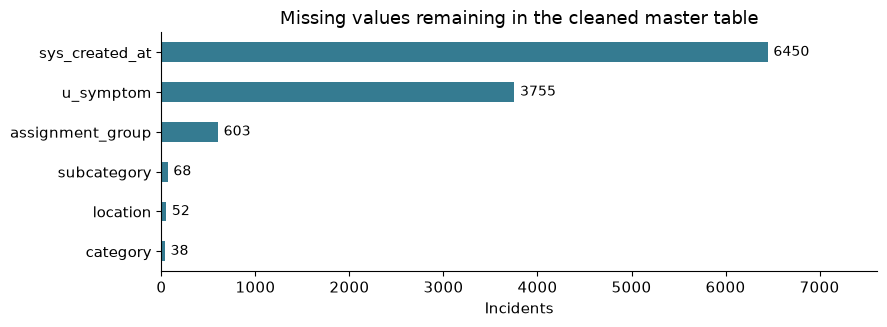

In [7]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
missing = processed.isna().sum()
missing = missing[missing > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 3.4))
missing.plot.barh(ax=ax, color="#357b91")
ax.set(title="Missing values remaining in the cleaned master table", xlabel="Incidents", ylabel="")
ax.bar_label(ax.containers[0], padding=4, fontsize=10)
ax.margins(x=0.18)
plt.tight_layout()
plt.show()

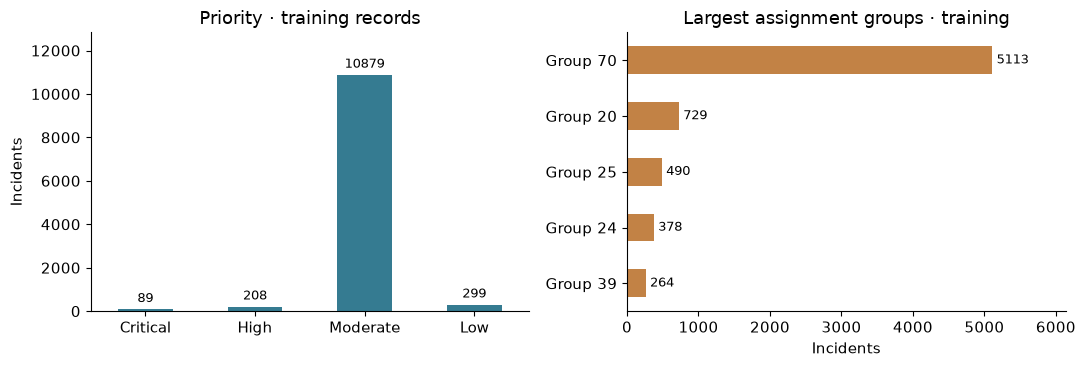

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
priority = tasks["priority"]["training_support"].sort_index()
priority.index = [label.split(" - ")[1] for label in priority.index]
priority.plot.bar(ax=axes[0], color="#357b91", rot=0)
axes[0].set(title="Priority · training records", ylabel="Incidents", xlabel="")
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
axes[0].margins(y=0.18)
groups = tasks["assignment_group"]["training_support"].head(5).sort_values()
groups.plot.barh(ax=axes[1], color="#c28245")
axes[1].set(title="Largest assignment groups · training", xlabel="Incidents", ylabel="")
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=9)
axes[1].margins(x=0.2)
plt.tight_layout()
plt.show()


Class weights are calculated from training labels for CW2. Rare groups remain intact; no prediction models are trained.

*Source: [UCI incident event log](https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log). Synthetic noise and code are AI-assisted.*